# 08a — Day 8a Evaluation: Speed Augmentation + Session-Fusion on WavLM Layer 6

**Standalone**, same pattern as `06_evaluate_combined.ipynb` — duplicated helper functions, applies
Day 5/6's exact recipe (speed-perturbation augmentation, optionally combined with PCA and/or
session-level fusion) to Day 7's winning embedding, **WavLM-base-plus layer 6**, instead of HuBERT
L12.

**Why this day exists:** Day 7 found WavLM layer 6 alone (0.663, CI [0.600, 0.710]) clearly beats
HuBERT's confirmed best (0.611) and nearly matches Day 6's fully-optimized combined HuBERT pipeline
(0.651) — with no augmentation or fusion at all. This tests whether the same recipe that took
HuBERT from 0.611 to 0.651 pushes WavLM even further past its own strong 0.663 starting point.

**Four configurations, same discipline as Day 6 (one variable at a time before combining):**
1. Augmented WavLM L6 alone (no PCA, no fusion).
2. Augmented WavLM L6 + PCA (isolated).
3. Augmented WavLM L6 + session-level fusion (isolated).
4. Augmented WavLM L6 + session-fusion + PCA (combined).

**No permutation test in this notebook** — per the project's discipline since Day 1, that's reserved
for a single finalized candidate. Day 10 is the designated buffer day: it picks the overall winner
across Days 7-9 (this day's four configs, Day 8b's fusion experiments, Day 9's augmentation
variants) and runs the one reserved permutation test on it. This day only logs results honestly,
win or lose, same as every exploratory day so far.

**The augmentation-leakage rule, unchanged from Day 5/6:** augmented copies only ever enrich a
*training* pool. Whenever a participant is scored — as the outer test fold, or as an inner-CV
validation fold — only their original, unperturbed recordings are used.

**Inputs needed (Kaggle "Add Input") — 3 total:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 7's `07_features_wavlm.ipynb`** output — for `wavlm_base_plus_all_layers.parquet`
   (original/unperturbed layer-6 embeddings).
3. **`08a_features_wavlm_augmented.ipynb`**'s output — for `wavlm_layer6_speed_augmented.parquet`
   (the 0.9x/1.1x embeddings).

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
LAYER = 6

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
WAVLM_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("wavlm_base_plus_all_layers.parquet"))
AUGMENTED_PARQUET = next(Path("/kaggle/input").rglob("wavlm_layer6_speed_augmented.parquet"))

print(f"LABELS_CSV                = {LABELS_CSV}")
print(f"WAVLM_ALL_LAYERS_PARQUET  = {WAVLM_ALL_LAYERS_PARQUET}")
print(f"AUGMENTED_PARQUET         = {AUGMENTED_PARQUET}")

LABELS_CSV                = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
WAVLM_ALL_LAYERS_PARQUET  = /kaggle/input/notebooks/tapudatta/notebook1-day7/features/wavlm_base_plus_all_layers.parquet
AUGMENTED_PARQUET         = /kaggle/input/notebooks/tapudatta/notebook1-day8a/features/wavlm_layer6_speed_augmented.parquet


## 1. Combine Original + Augmented Embeddings

Identical shape to `06_evaluate_combined.ipynb` section 1 — pulls layer 6 out of Day 7's all-layers
file (tagged `speed_factor=1.0`), concatenates with the 0.9x/1.1x augmented embeddings. Kept at the
recording grain (not collapsed to just `X`/`y`/`groups`) because the session-fusion configuration
needs `session_number` and `activity_type` to know which rows to concatenate.

In [2]:
labels = pd.read_csv(LABELS_CSV)
wavlm_all_layers = pd.read_parquet(WAVLM_ALL_LAYERS_PARQUET)
augmented = pd.read_parquet(AUGMENTED_PARQUET)

layer_cols = [c for c in wavlm_all_layers.columns if c.startswith(f"layer{LAYER}_emb_")]
assert len(layer_cols) == 1536, f"expected 1536 layer-{LAYER} columns, got {len(layer_cols)}"
original_layer6 = wavlm_all_layers[["filename"] + layer_cols].copy()
original_layer6.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]
original_layer6["speed_factor"] = 1.0

augmented = augmented.rename(columns={"source_filename": "filename"})

combined_emb = pd.concat([original_layer6, augmented], ignore_index=True, sort=False)
assert len(combined_emb) == 280 * 3, f"expected 840 combined rows, got {len(combined_emb)}"

df_aug = labels.merge(combined_emb, on="filename", how="inner").reset_index(drop=True)
assert len(df_aug) == 280 * 3, f"expected 840 rows after merge, got {len(df_aug)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df_aug["y"] = df_aug["label"].map(LABEL_MAP)
assert df_aug["y"].isna().sum() == 0
df_aug["is_original"] = df_aug["speed_factor"] == 1.0

per_filename_participants = df_aug.groupby("filename")["participant_id"].nunique()
assert (per_filename_participants == 1).all(), \
    "a filename maps to more than one participant_id across its speed variants -- bug"

emb_cols = [c for c in df_aug.columns if c.startswith("emb_")]
X = df_aug[emb_cols].to_numpy()
y = df_aug["y"].to_numpy()
groups = df_aug["participant_id"].to_numpy()
is_original = df_aug["is_original"].to_numpy()

print(f"Total rows: {len(df_aug)} (280 original + 560 augmented)")
print(f"X: {X.shape}, original rows: {is_original.sum()}, augmented rows: {(~is_original).sum()}")
print("Checked: every recording's original + augmented copies share exactly one participant_id.")

Total rows: 840 (280 original + 560 augmented)
X: (840, 1536), original rows: 280, augmented rows: 560
Checked: every recording's original + augmented copies share exactly one participant_id.


## 2. Shared Candidates, Pipelines & Augmentation-Aware Nested CV

Identical machinery to `06_evaluate_combined.ipynb` section 2 (duplicated here since this notebook
is standalone) — `build_pipeline_pca`, `make_candidates_plain` (10 candidates, no PCA),
`make_candidates_pca` (30 candidates, same 10/30/50 component grid), and
`nested_loso_cv_augmented_variant` (augmentation-aware masking: training pools get original +
augmented rows, every scored fold uses original rows only). `run_variant` wraps the CV, computes
pooled AUC + bootstrap CI, and logs each configuration into `results_log`.

In [3]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline_pca(model_name: str, c: float, pca_components: int | None = None) -> Pipeline:
    steps = [("scaler", StandardScaler())]
    if pca_components is not None:
        steps.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_SEED)))
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    steps.append(("clf", clf))
    return Pipeline(steps)


def make_candidates_plain():
    return [
        (f"{name}_C={c}", build_pipeline_pca(name, c, pca_components=None))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def make_candidates_pca(pca_options=(10, 30, 50)):
    return [
        (f"{name}_C={c}_pca={k}", build_pipeline_pca(name, c, pca_components=k))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
        for k in pca_options
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [4]:
def nested_loso_cv_augmented_variant(X, y, groups, is_original, make_candidates_fn,
                                      n_inner_splits=6, expected_n_scored=None):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    oof_preds = np.full(len(y), -1)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = (groups == test_participant) & is_original
        outer_train_mask = groups != test_participant

        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]        # original + augmented
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]    # original only
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)   # trained on original + augmented
        test_scores = score_fn(final_pipe, X_te)             # scored on original only

        test_positions = np.where(outer_test_mask)[0]
        oof_scores[test_positions] = test_scores
        oof_preds[test_positions] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "n_train": int(outer_train_mask.sum()),
            "chosen_label": best_label,
            "chosen_template": best_template,
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = int(np.sum(~np.isnan(oof_scores)))
    print(f"  Scored {n_scored} original rows.")
    if expected_n_scored is not None:
        assert n_scored == expected_n_scored, f"expected {expected_n_scored} scored rows, got {n_scored}"
    return oof_scores, oof_preds, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


def summarize(y, oof_scores, groups):
    valid = ~np.isnan(oof_scores)
    y_v, s_v, g_v = y[valid], oof_scores[valid], groups[valid]
    auc = roc_auc_score(y_v, s_v)
    lo, hi, _ = bootstrap_auc_ci(g_v, y_v, s_v)
    return auc, lo, hi, int(valid.sum())


results_log = []
variant_artifacts = {}


def run_variant(name, X_in, y_in, groups_in, is_original_in, meta_df, make_candidates_fn,
                expected_n_scored=None):
    print(f"=== {name} ===")
    oof_scores, oof_preds, fold_info = nested_loso_cv_augmented_variant(
        X_in, y_in, groups_in, is_original_in, make_candidates_fn, expected_n_scored=expected_n_scored
    )
    auc, ci_lo, ci_hi, n_scored = summarize(y_in, oof_scores, groups_in)
    print(f"  Pooled AUC = {auc:.3f}  (95% CI [{ci_lo:.3f}, {ci_hi:.3f}], N={n_scored})\n")
    results_log.append({"variant": name, "N": n_scored, "auc": auc, "ci_lo": ci_lo, "ci_hi": ci_hi})
    variant_artifacts[name] = {
        "X": X_in, "y": y_in, "groups": groups_in, "is_original": is_original_in,
        "fold_info": fold_info, "meta_df": meta_df.reset_index(drop=True),
    }
    return auc

## 3. Configuration #1 — Augmented WavLM L6 (no PCA, no fusion)

The direct analog of Day 5's HuBERT result — does adding speed-perturbed training copies help
WavLM layer 6 the same way it helped HuBERT (0.611 -> 0.639)? No prior exact number to sanity-check
against here (unlike Day 6's reproduction of Day 5), since this is the first time WavLM L6 is
combined with augmentation — but the result should be in the same neighborhood as Day 7's plain
0.663, moving up or down depending on whether the added training volume outweighs the
tempo-invariance cost, same trade-off Day 5 flagged for HuBERT.

In [5]:
meta_recording = df_aug[["participant_id", "session_number", "y"]]

auc_baseline = run_variant(
    "Augmented WavLM L6 (no PCA, no fusion)",
    X, y, groups, is_original, meta_recording, make_candidates_plain, expected_n_scored=280,
)
print("Reference -- Day 7 plain WavLM L6 (no augmentation): AUC 0.663, CI [0.600, 0.710]")
print("Reference -- Day 6 final HuBERT pipeline: AUC 0.651, CI [0.584, 0.720], permutation p=0.0020")

=== Augmented WavLM L6 (no PCA, no fusion) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
  Pooled AUC = 0.643  (95% CI [0.590, 0.701], N=280)

Reference -- Day 7 plain WavLM L6 (no augmentation): AUC 0.663, CI [0.600, 0.710]
Reference -- Day 6 final HuBERT pipeline: AUC 0.651, CI [0.584, 0.720], permutation p=0.0020


## 4a. Configuration #2 — Augmented WavLM L6 + PCA (isolated)

Same PCA mechanics as Day 6 section 4a — fit fresh inside every fold's training pool (original +
augmented rows together), 10/30/50 components swept. Day 6 found PCA hurt HuBERT once augmentation
already relieved the `p >> n` problem; worth re-testing rather than assuming the same holds for a
different embedding with potentially different variance structure.

In [6]:
auc_pca = run_variant(
    "Augmented WavLM L6 + PCA (10/30/50 components)",
    X, y, groups, is_original, meta_recording, make_candidates_pca, expected_n_scored=280,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")

=== Augmented WavLM L6 + PCA (10/30/50 components) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
  Pooled AUC = 0.595  (95% CI [0.549, 0.656], N=280)

vs. baseline (config #1): 0.643


## 4b. Configuration #3 — Augmented WavLM L6 + Session-Level Fusion (isolated)

Identical construction to Day 6 section 4b: concatenate a session's three activity embeddings into
one 4608-dim vector, built separately per speed factor (a session's 1.0x/0.9x/1.1x fused vectors
each concatenate that speed's three activity embeddings — never mixed across speeds, same
same-speed-factor-per-session design decision as Day 6). Only 1.0x fused sessions are ever scored;
0.9x/1.1x fused sessions enrich training pools only.

In [7]:
ACTIVITY_ORDER = ["read_aloud", "read_aloud_nonsense", "describe_picture"]


def build_session_features_augmented(df_aug, emb_cols):
    rows = []
    for (participant, session, speed), group in df_aug.groupby(
        ["participant_id", "session_number", "speed_factor"]
    ):
        by_activity = group.set_index("activity_type")
        if not all(a in by_activity.index for a in ACTIVITY_ORDER):
            continue  # incomplete session (missing an activity) -- skip, nothing to concatenate
        feats = np.concatenate([by_activity.loc[a, emb_cols].to_numpy(dtype=float) for a in ACTIVITY_ORDER])
        rows.append({
            "participant_id": participant,
            "session_number": session,
            "speed_factor": speed,
            "y": int(by_activity["y"].iloc[0]),
            "is_original": bool(speed == 1.0),
            "features": feats,
        })
    return pd.DataFrame(rows)


session_feat_df = build_session_features_augmented(df_aug, emb_cols)
X_session_aug = np.vstack(session_feat_df["features"].to_numpy())
y_session_aug = session_feat_df["y"].to_numpy()
groups_session_aug = session_feat_df["participant_id"].to_numpy()
is_original_session_aug = session_feat_df["is_original"].to_numpy()
meta_session = session_feat_df[["participant_id", "session_number", "y"]]

n_original_sessions = int(is_original_session_aug.sum())
total_combos = df_aug.groupby(["participant_id", "session_number", "speed_factor"]).ngroups
print(f"Session x speed-factor dataset: {X_session_aug.shape}")
print(f"{len(session_feat_df)}/{total_combos} complete session-speed combos used "
      f"({total_combos - len(session_feat_df)} dropped for a missing activity)")
print(f"{n_original_sessions} of these are original (speed=1.0) -- this is what gets scored; "
      f"the remaining {len(session_feat_df) - n_original_sessions} (0.9x/1.1x) enrich training pools only.")

Session x speed-factor dataset: (276, 4608)
276/282 complete session-speed combos used (6 dropped for a missing activity)
92 of these are original (speed=1.0) -- this is what gets scored; the remaining 184 (0.9x/1.1x) enrich training pools only.


In [8]:
auc_fusion = run_variant(
    "Augmented WavLM L6 + session-level fusion",
    X_session_aug, y_session_aug, groups_session_aug, is_original_session_aug,
    meta_session, make_candidates_plain, expected_n_scored=n_original_sessions,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")
print(f"vs. Day 6's HuBERT session-fusion result: 0.651, CI [0.584, 0.720]")

=== Augmented WavLM L6 + session-level fusion ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
  Pooled AUC = 0.638  (95% CI [0.596, 0.713], N=92)

vs. baseline (config #1): 0.643
vs. Day 6's HuBERT session-fusion result: 0.651, CI [0.584, 0.720]


## 4c. Configuration #4 — Augmented WavLM L6 + Session-Fusion + PCA (combined)

Built unconditionally (same stated caveat as Day 6 section 4c): a win here only means something if
#2 and/or #3 also won individually. If neither did, treat a #4 win as a small-N combination
artifact worth reporting, not a confirmed synergy.

In [9]:
auc_combined = run_variant(
    "Augmented WavLM L6 + session-fusion + PCA (combined)",
    X_session_aug, y_session_aug, groups_session_aug, is_original_session_aug,
    meta_session, make_candidates_pca, expected_n_scored=n_original_sessions,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")
print(f"vs. PCA alone (config #2): {auc_pca:.3f}")
print(f"vs. session-fusion alone (config #3): {auc_fusion:.3f}")

=== Augmented WavLM L6 + session-fusion + PCA (combined) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
  Pooled AUC = 0.631  (95% CI [0.553, 0.724], N=92)

vs. baseline (config #1): 0.643
vs. PCA alone (config #2): 0.595
vs. session-fusion alone (config #3): 0.638


## 5. Day 8a Results

                                             variant   N      auc    ci_lo    ci_hi
              Augmented WavLM L6 (no PCA, no fusion) 280 0.643292 0.589686 0.701190
      Augmented WavLM L6 + PCA (10/30/50 components) 280 0.595008 0.548928 0.655504
           Augmented WavLM L6 + session-level fusion  92 0.637874 0.596483 0.712512
Augmented WavLM L6 + session-fusion + PCA (combined)  92 0.630755 0.553223 0.724224


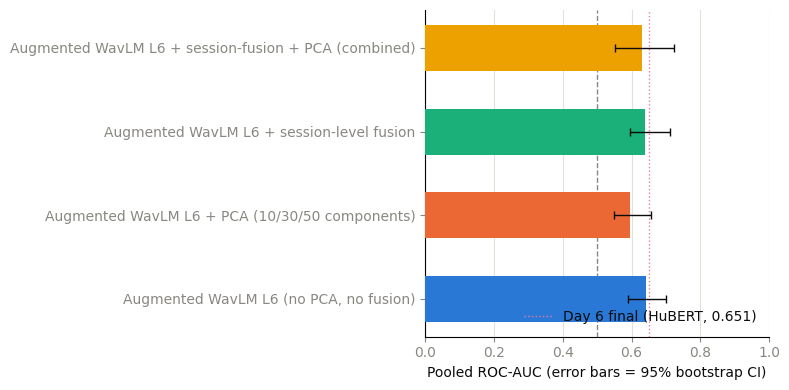


Best Day 8a configuration: Augmented WavLM L6 (no PCA, no fusion)  AUC=0.643  CI=[0.590, 0.701]
No permutation test run here -- reserved for Day 10's final buffer.


In [10]:
results_df = pd.DataFrame(results_log)
print(results_df.to_string(index=False))

DAY8A_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=DAY8A_COLORS[: len(results_df)], height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.axvline(0.651, color="#e87ba4", linewidth=1, linestyle=":", zorder=2, label="Day 6 final (HuBERT, 0.651)")
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
plt.tight_layout()
plt.show()

best_idx = results_df["auc"].idxmax()
print(f"\nBest Day 8a configuration: {results_df.loc[best_idx, 'variant']}  "
      f"AUC={results_df.loc[best_idx, 'auc']:.3f}  "
      f"CI=[{results_df.loc[best_idx, 'ci_lo']:.3f}, {results_df.loc[best_idx, 'ci_hi']:.3f}]")
print("No permutation test run here -- reserved for Day 10's final buffer.")

## How to read Day 8a's results

- **Best config clearly beats both Day 7's plain WavLM L6 (0.663) and Day 6's final HuBERT pipeline
  (0.651)**, with the CI lower bound moving up too (not just the point estimate): this becomes the
  new leading candidate carried into Day 10's shortlist, alongside whatever Day 8b (embedding
  fusion) and Day 9 (pitch-shift/mixup) find.
- **Best config is close to 0.663 with substantially overlapping CIs**: augmentation/fusion didn't
  clearly add anything beyond WavLM L6 alone — carry Day 7's simpler plain-WavLM-L6 result into
  Day 10's shortlist instead, per Simplicity First.
- **Best config is *below* 0.663**: consistent with the tempo-invariance risk Day 5 originally
  flagged (speaking rate is a documented real fatigue marker; forcing invariance to it can hurt if
  the embedding leans on it more than HuBERT did) — report honestly and carry Day 7's plain WavLM L6
  result forward instead.
- **If config #4 (combined) wins but neither #2 nor #3 did individually**, flag that as a weak,
  decomposition-inconsistent result per the same caveat Day 6 applied.

**No permutation test yet** — Day 10 picks the single best candidate across Days 7-9 and runs the
one reserved permutation test on it. Update `PROJECT_PLAN.md`'s Day 7+ roadmap section with today's
four numbers before moving to Day 8b.